[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/arvidl/BMED365-2027/blob/main/Lab5-Comp-Mod/Kiwi-challenge/notebooks/00-kiwi-math-primer-for-biomedicine.ipynb)

# The Computational Kiwi Challenge (Step 0): A Visual Mathematical Primer for Biomedicine & Clinicians

**BMED365 — Computational Imaging, Modeling and AI in Biomedicine (Lab 5, Spring 2027)**  
*Arvid Lundervold — self-contained visual tutorial (`< 5 s` runtime, zero external downloads) — runs locally with `uv` or in Google Colab*

> **Lab 5 (`Lab5-Comp-Mod/Kiwi-challenge`) Sequence — Start Here if Equations Look Intimidating!**
> - **`00-kiwi-math-primer-for-biomedicine.ipynb` (this notebook)** — A welcoming, intuition-first **"Mathematical Rosetta Stone"** translating every symbol and modeling tool used in Lab 5 into plain clinical English, everyday analogies, and tiny 5-line visual Python toys.
> - [`00a-kiwi-anatomical-and-physiological-atlas.ipynb`](./00a-kiwi-anatomical-and-physiological-atlas.ipynb) — **Step 0a (`Lab 4 ↔ Lab 5` Multi-Scale Atlas):** Macroscopic optical vs. 3-plane 7T MRI contrast inversion, $\mu\text{m}$-scale histology, dioecious `XY` flowers, `BBCH` life cycle, & 160-day physiology.
> - [`01-kiwi-growth-and-morphogenesis.ipynb`](./01-kiwi-growth-and-morphogenesis.ipynb) — **Part 1 (Forward Modeling):** Algebraic receptor saturation $\to$ bistable `XY` sex-switch & 160-day biophysical growth ODEs $\to$ 1D Ring Turing & 2D paracrine hormone PDEs, tested directly on our **[Lab 4 (`2005 7T MRI`)](../../../Lab4-Comp-Imag/Kiwi-challenge/README.md)** scan.
> - [`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb) — **Part 2 (Quantitative Research & Digital Twin):** Polyploid Turing stability, 3D spatial point-process statistics, ill-posed PDE inverse problems (`Tikhonov`), and a generative 3D Bloch-MRI Digital Twin.

---

## 0. Why This Notebook Exists — And How to Read Mathematical Notation Without Fear

If you trained in **medicine, biology, pharmacy, nursing, or wet-lab biomedical research**, hitting a wall of Greek letters, upside-down triangles ($\nabla^2$), and optimization operators ($\arg\min$) can feel like walking into a lecture delivered in an unfamiliar alphabet.

Here is the secret that mathematicians and physicists rarely tell students upfront:

> **Almost every intimidating mathematical symbol in biomedical modeling is just compact shorthand for a simple Python `for`-loop or one-line array operation — like summing a list, comparing today's lab value with yesterday's, or comparing one cell with its immediate neighbors.**

You do **not** need years of hand-worked calculus tricks to understand mechanistic models in modern biomedicine, because **the computer does the arithmetic**. Your job as a biomedical scientist or clinician is to understand **what biological mechanism each term expresses**, **what happens at extreme values**, and **when a model's assumptions fail**.

### Learning Outcomes
After spending ~25 minutes with the six visual toys in this primer, you will be able to:
1. **Decode mathematical notation at a glance:** Translate $\sum$, $\int$, $\frac{dy}{dt}$, $\frac{\partial c}{\partial t}$, $\nabla^2 c$, $\|\mathbf{x}\|_2$, $\arg\min$, and $\text{Re}\,\lambda$ into plain clinical language and 1-line `NumPy` code.
2. **Read saturation & Hill equations without algebra:** Use the *"three test numbers"* trick (`0`, `K`, `huge`) to read $\text{EC}_{50}$ / $K_d$ and cooperativity $n$ right off an equation.
3. **Read Ordinary Differential Equations (`ODEs`) as balance sheets:** Interpret $\frac{dy}{dt} = \text{In} - \text{Out}$ as a 4-line update loop, find steady states ($\frac{dy}{dt}=0$), and explain how positive feedback creates **bistable cell-fate valleys**.
4. **Demystify Partial Differential Equations (`PDEs`) & $\nabla^2$:** Compute the Laplacian $\nabla^2 c$ in your head as *"neighbors minus me"*, interpret paracrine decay length $\ell = \sqrt{D/k}$, and explain **Turing's "local cheerleader + fast firefighter"** pattern generator.
5. **Judge spatial randomness vs. repulsion:** Explain why true randomness (`CSR`) looks clumpy to the human eye and how nearest-neighbor curves $G(r)$ detect physical "personal space" (`hard-core repulsion`).
6. **Understand inverse regularization & Rician MRI noise:** Explain why naive un-blurring explodes on `1%` noise (`ill-posedness`), how Tikhonov's $\lambda$ knob tames it, and why squaring noisy MRI channels lifts dark voxels above zero.

---

### The Mathematical Symbol "Rosetta Stone"

Keep this table handy as a bookmark while reading Notebooks `01`, `02`, and the other `Lab 5` physiological models:

| Mathematical Shorthand | How to Say It Aloud | Plain-English / Clinical Meaning | Exact 1-Line Python / NumPy Equivalent | Where You Meet It in Lab 5 |
| :--- | :--- | :--- | :--- | :--- |
| $\displaystyle\sum_{i=1}^{N} x_i$ | *"Sum of $x_i$ from $1$ to $N$"* | Add up every measurement in a list (e.g., sum 128 slice areas to get total 3D organ volume) | `np.sum(x)` | `NB 01` Sec. 2 (3D MRI volume) |
| $\displaystyle\prod_{i=1}^{N} p_i$ | *"Product of $p_i$ from $1$ to $N$"* | Multiply factors together (e.g., probability that $N$ independent events all happen) | `np.prod(p)` | `NB 02` (independent probabilities) |
| $\displaystyle\int_{0}^{T} r(t)\,dt$ | *"Integral of $r(t)$ from $0$ to $T$"* | Total accumulated amount = **Area Under the Curve (`AUC`)** (e.g., total drug exposure or total organ growth over 160 days) | `np.trapezoid(r, t)` | `NB 01` Stage 2B & `07-dce-mri` |
| $\displaystyle\frac{dy}{dt}$ | *"Derivative of $y$ with respect to time $t$"* | **Net speed of change right now:** $(\text{Rate In}) - (\text{Rate Out})$, in units of $[\text{amount per day}]$ | `y_next = y + dt * net_rate` | `NB 01` Stages 2A, 2B & `01`–`08` |
| $\displaystyle\frac{\partial c}{\partial t}$ | *"Partial derivative of $c(x,t)$ over time"* | Speed of concentration change **at one fixed tissue pixel $x$** while holding position frozen | `(c_next[x] - c[x]) / dt` | `NB 01` Stage 3A & `08-wound` |
| $\nabla c$ | *"Gradient of $c$"* | An arrow pointing **uphill** toward higher concentration; arrow length = how steep the slope is | `np.gradient(c, dx)` | `NB 01` Stage 3B (hormone flux) |
| $\nabla^2 c$ | *"Laplacian of $c$"* | **Neighbor comparison:** positive in a local dip (`neighbors > me` $\to$ fills in); negative on a local peak (`neighbors < me` $\to$ flattens out) | `ndi.laplace(c) / dx**2` | `NB 01` Stages 3A, 3B & `NB 02` |
| $\lVert\mathbf{x} - \mathbf{y}\rVert_2$ | *"Euclidean ($L_2$) distance / norm"* | Straight-line 3D ruler distance $\sqrt{\Delta x^2 + \Delta y^2 + \Delta z^2}$ (or root-sum-of-squares error between model and data) | `np.linalg.norm(x - y)` | `NB 02` Mod. 2 & Mod. 3 |
| $\displaystyle\arg\min_{\mathbf{x}} J(\mathbf{x})$ | *"Arg-min over $\mathbf{x}$ of $J(\mathbf{x})$"* | *"Search all candidate inputs $\mathbf{x}$ and return **which $\mathbf{x}$** gives the lowest penalty score $J(\mathbf{x})$"* | `x_grid[np.argmin(J_scores)]` | `NB 02` Mod. 3 (inverse problem) |
| $\mathbb{E}[X]$ and $P(A \mid B)$ | *"Expected value of $X$"*; *"Prob. of $A$ given $B$"* | Long-run average across many repeats; probability of $A$ once we already know $B$ is true | `np.mean(samples)` | `NB 02` Mod. 2 (spatial stats) |
| $\text{Re}\,\lambda(q)$ | *"Real part of eigenvalue $\lambda$ at wavenumber $q$"* | **Ripple growth rate:** if $> 0$, a spatial wave with $q$ peaks amplifies into spots/stripes; if $< 0$, it dies away | `np.linalg.eigvals(J).real.max()` | `NB 02` Mod. 1 (carpel count) |

In [1]:
%matplotlib inline

import subprocess
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate, ndimage as ndi, spatial

try:
    import ipywidgets as widgets
    from IPython.display import display
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ipywidgets"])
    import ipywidgets as widgets
    from IPython.display import display

if "google.colab" in sys.modules:
    from google.colab import output as colab_output
    colab_output.enable_custom_widget_manager()

np.random.seed(42)
plt.rcParams["figure.dpi"] = 115
plt.rcParams["axes.titlesize"] = 10.5

# Tiny 5-number demonstration of the Rosetta Stone in plain Python:
x = np.array([2.0, 2.0, 10.0, 2.0, 2.0])  # e.g., hormone level in 5 adjacent cells
t = np.array([0.0, 1.0, 2.0, 3.0, 4.0])   # hours

print("5 adjacent cell values x           :", x)
print("Sum       ∑ x_i   = np.sum(x)      :", np.sum(x))
print("Average   E[x]    = np.mean(x)     :", np.mean(x))
print("AUC       ∫ x dt  = np.trapezoid   :", np.trapezoid(x, t))
print("Peak idx  argmax  = np.argmax(x)   :", int(np.argmax(x)), f"(value = {x[np.argmax(x)]})")
print("1D Laplacian ∇²x at center cell #2 :", (x[1] + x[3] - 2 * x[2]), " (negative -> peak diffuses outward!)")

5 adjacent cell values x           : [ 2.  2. 10.  2.  2.]
Sum       ∑ x_i   = np.sum(x)      : 18.0
Average   E[x]    = np.mean(x)     : 3.6
AUC       ∫ x dt  = np.trapezoid   : 16.0
Peak idx  argmax  = np.argmax(x)   : 2 (value = 10.0)
1D Laplacian ∇²x at center cell #2 : -16.0  (negative -> peak diffuses outward!)


---

## 1. Stepping Stone 1: Receptor Saturation & Cooperative Switches ($f(x) = \frac{x^n}{K^n + x^n}$)

### 1.1 Everyday & Clinical Intuition: *"Musical Chairs on Cell Receptors"*
Imagine a hospital ward with **100 beds** (or a cell surface carrying **100 hormone receptors**):
- When the first few patients arrive (low hormone/drug concentration $x$), almost every arrival finds an empty bed immediately — occupancy rises steeply and linearly with $x$.
- When **50 beds are already full**, half the capacity is used ($x = K$).
- When **99 beds are full**, sending 10 times more ambulances **cannot** put 1,000 patients into 100 beds! The response hits a **ceiling (saturation)**.

Biology writes this universal "diminishing returns" curve — called **Michaelis–Menten** ($n=1$) or **Hill saturation** ($n \ge 1$) — as a simple fraction:

$$f_{\text{act}}(x) = \frac{x^n}{K^n + x^n} \qquad \text{(Activation)}, \qquad\qquad f_{\text{rep}}(x) = \frac{1}{1 + (x/K)^n} = \frac{K^n}{K^n + x^n} \qquad \text{(Repression)}$$

### 1.2 The "Three Test Numbers" Reading Trick (Zero Algebra Required!)
Whenever you encounter a fraction in a paper or notebook, **plug in three easy test numbers** for the signal $x$:
1. **Zero signal ($x = 0$):** $f_{\text{act}}(0) = \frac{0}{K^n + 0} = \mathbf{0}$ (0% response); $f_{\text{rep}}(0) = \mathbf{1}$ (100% unrepressed).
2. **Half-saturation ($x = K$):** $f_{\text{act}}(K) = \frac{K^n}{K^n + K^n} = \mathbf{\frac{1}{2}}$ (**50% response, for *any* $n$!**). Thus **$K$ has the exact same physical units as $x$** ($\text{nM}$, $\text{mg/L}$, or seed count) and simply marks the **50% midpoint** ($\text{EC}_{50}$, $\text{IC}_{50}$, or $K_d$).
3. **Huge signal ($x \gg K$):** $K^n$ becomes tiny next to $x^n$, so $\frac{x^n}{K^n + x^n} \approx \frac{x^n}{x^n} = \mathbf{1}$ (100% saturated ceiling).

**What does the Hill exponent $n$ control?**
- **$n = 1$ (Non-cooperative / graded dimmer switch):** Smooth hyperbolic curve — e.g., standard single-site drug binding, or how **seed count $N$ drives kiwifruit volume $V(N)$** in `Notebook 01` Stage 1 (`K_N ≈ 280` seeds).
- **$n = 4$ (Cooperative / sharp digital toggle switch):** First binding event makes the next ones easier (like **4 $\text{O}_2$ molecules binding human hemoglobin**, or transcription-factor dimers/tetramers). Below $K$ the gene is nearly OFF; above $K$ it snaps ON — used by kiwifruit's Y-chromosome gene ***Shy Girl* (`SyGI`)** to shut down female ovary formation in `Notebook 01` Stage 2A!

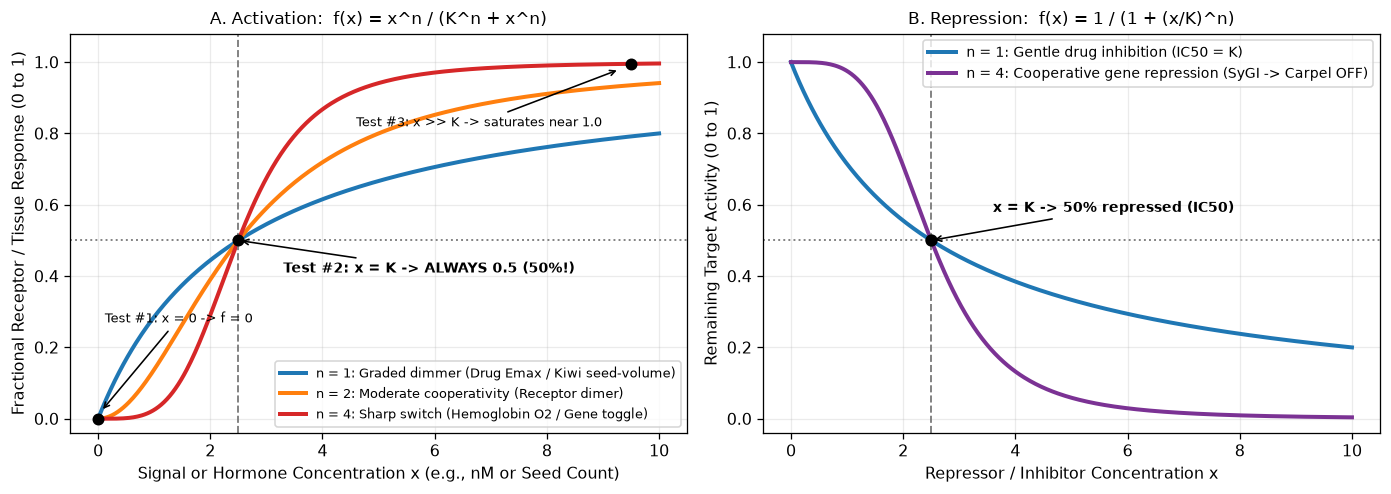

In [2]:
x_conc = np.linspace(0, 10, 400)
K_half = 2.5  # Half-maximal concentration (EC50 / IC50), same units as x

fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))

# Panel A: Activation curves (n = 1, 2, 4)
for n_hill, col, lbl in [
    (1, "#1f77b4", "n = 1: Graded dimmer (Drug Emax / Kiwi seed-volume)"),
    (2, "#ff7f0e", "n = 2: Moderate cooperativity (Receptor dimer)"),
    (4, "#d62728", "n = 4: Sharp switch (Hemoglobin O2 / Gene toggle)"),
]:
    y_act = (x_conc**n_hill) / (K_half**n_hill + x_conc**n_hill)
    axes[0].plot(x_conc, y_act, lw=2.5, color=col, label=lbl)

axes[0].axvline(K_half, color="gray", ls="--", lw=1.2)
axes[0].axhline(0.5, color="gray", ls=":", lw=1.2)
axes[0].scatter([0, K_half, 9.5], [0, 0.5, (9.5**4) / (K_half**4 + 9.5**4)], color="black", zorder=5, s=42)
axes[0].annotate("Test #1: x = 0 -> f = 0", xy=(0.05, 0.02), xytext=(0.12, 0.27),
                 arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=8.3)
axes[0].annotate("Test #2: x = K -> ALWAYS 0.5 (50%!)", xy=(K_half, 0.5), xytext=(3.3, 0.41),
                 arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=8.5, fontweight="bold")
axes[0].annotate("Test #3: x >> K -> saturates near 1.0", xy=(9.3, 0.98), xytext=(4.6, 0.82),
                 arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=8.3)
axes[0].set_title("A. Activation:  f(x) = x^n / (K^n + x^n)")
axes[0].set_xlabel("Signal or Hormone Concentration x (e.g., nM or Seed Count)")
axes[0].set_ylabel("Fractional Receptor / Tissue Response (0 to 1)")
axes[0].set_ylim(-0.04, 1.08)
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(alpha=0.25)

# Panel B: Repression curves (how an inhibitor or Y-linked SyGI shuts down a target)
for n_hill, col, lbl in [
    (1, "#1f77b4", "n = 1: Gentle drug inhibition (IC50 = K)"),
    (4, "#7b3294", "n = 4: Cooperative gene repression (SyGI -> Carpel OFF)"),
]:
    y_rep = 1.0 / (1.0 + (x_conc / K_half) ** n_hill)
    axes[1].plot(x_conc, y_rep, lw=2.5, color=col, label=lbl)

axes[1].axvline(K_half, color="gray", ls="--", lw=1.2)
axes[1].axhline(0.5, color="gray", ls=":", lw=1.2)
axes[1].scatter([K_half], [0.5], color="black", zorder=5, s=45)
axes[1].annotate("x = K -> 50% repressed (IC50)", xy=(K_half, 0.5), xytext=(3.6, 0.58),
                 arrowprops=dict(arrowstyle="->", lw=1.0), fontsize=8.5, fontweight="bold")
axes[1].set_title("B. Repression:  f(x) = 1 / (1 + (x/K)^n)")
axes[1].set_xlabel("Repressor / Inhibitor Concentration x")
axes[1].set_ylabel("Remaining Target Activity (0 to 1)")
axes[1].set_ylim(-0.04, 1.08)
axes[1].legend(fontsize=8.5, loc="upper right")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Plain-Language Takeaway from Figure 1
- Look at **Fig. 1A**: all three curves ($n=1, 2, 4$) pass through the **exact same bullseye at $(x = K,\; f = 0.5)$**. Changing $K$ slides the curve left or right (potency); changing $n$ tilts the slope at the midpoint from a gentle ramp ($n=1$) into a cliff-like ON/OFF switch ($n=4$).
- Look at **Fig. 1B**: flipping $x^n$ in the numerator to $K^n$ turns an **activator** into a **repressor** ($1 - f_{\text{act}}(x)$) that starts at `1.0` when $x=0$ and shuts off toward `0` when $x \gg K$.

<details>
<summary><b>Check Your Intuition #1 (Click to reveal answer):</b> In Notebook 01, a kiwifruit needs <code>K_N = 280</code> seeds to reach half of its seed-driven volume boost (<code>n = 1</code>). Why does going from <code>1,100</code> to <code>1,440</code> seeds barely change fruit size, whereas dropping from <code>280</code> to <code>50</code> seeds shrinks the fruit dramatically?</summary>

- At `1,100` seeds ($x \approx 4 K_N$), plug into the formula: $\frac{4}{1 + 4} = 80\%$ of receptors/sink capacity are already saturated, and at `1,440` seeds ($x \approx 5.1 K_N$), $\frac{5.1}{1 + 5.1} = 84\%$ — only a **4% gain** because the tissue is on the flat upper plateau ("almost all hospital beds are already full")!
- By contrast, dropping from `280` seeds ($50\%$) down to `50` seeds ($\frac{50}{280+50} = 15\%$) plunges the fruit down the steep left ramp of **Fig. 1A**. Biology uses that flat upper plateau for **developmental canalization** — guaranteeing uniform organ size despite normal pollination fluctuations!
</details>

---

## 2. Stepping Stone 2: Differential Equations (`ODEs`) & Bistable Cell-Fate Valleys ($\frac{dy}{dt} = \text{In} - \text{Out}$)

### 2.1 Everyday & Clinical Intuition: *"An IV Drip Into a Leaky Bucket"*
When a paper writes an **Ordinary Differential Equation (ODE)** like

$$\frac{dy}{dt} = \underbrace{k_{\text{in}}}_{\text{Production / IV infusion}} - \underbrace{k_{\text{out}}\,y}_{\text{Clearance / Degradation}}$$

do **not** try to integrate it in your head! Read $\frac{dy}{dt}$ literally as **"how fast the level in the bucket is rising or falling right now"**:
- If `Inflow > Outflow`, then $\frac{dy}{dt} > 0$ $\implies$ the level **rises** over the next small time step $\Delta t$.
- If `Inflow < Outflow`, then $\frac{dy}{dt} < 0$ $\implies$ the level **falls** over the next small time step $\Delta t$.
- If `Inflow == Outflow`, then $\frac{dy}{dt} = 0$ $\implies$ **steady state (homeostasis)**! Molecules are still entering and leaving every second, but the total level stays constant at $y^* = k_{\text{in}} / k_{\text{out}}$.

In Python, solving *any* ODE is conceptually just a **4-line `for` loop** (**Euler's method**):
```python
for step in range(num_steps):
    net_rate = k_in - k_out * y     # 1. Compute dy/dt right now
    y = y + dt * net_rate           # 2. Step forward by a tiny time slice dt!
```
*(Library solvers like `scipy.integrate.solve_ivp` simply take smarter, adaptive sub-steps so the curve stays ultra-accurate.)*

### 2.2 How Positive Feedback Creates "Two Valleys & a Tipping Point" (Bistability)
A leaky bucket has **one** steady state: if you stop the IV drip, the drug washes out. So how does a developing embryo make a **permanent binary decision** — becoming **Male vs. Female** (`SRY`/`SOX9` vs. `WNT4` in humans; `SyGI` vs. Carpel identity in kiwifruit) and staying committed for life?

By adding **cooperative positive self-feedback**: once gene $C$ crosses a critical threshold, it turns on its *own* promoter ($\text{Inflow} = b_0 + v_{\max}\frac{C^4}{K^4 + C^4}$). Just like **Conrad Waddington's (1957) epigenetic marble rolling down a landscape**, positive feedback carves **two stable valleys** (`OFF ≈ 0` and `ON ≈ 1`) separated by an unstable **hilltop tipping point (separatrix)**!

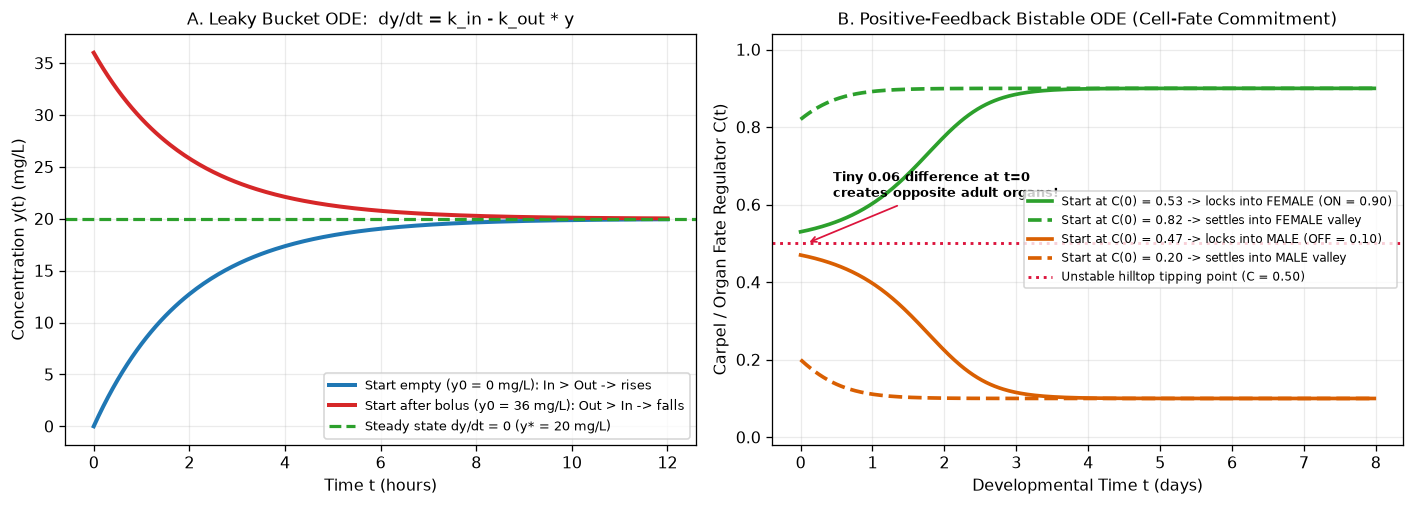

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.5))

# --- Panel A: Simple Leaky Bucket / IV Drug Infusion (1 Stable Steady State) ---
dt = 0.05
t_hours = np.arange(0, 12.0 + dt, dt)
k_in = 10.0    # mg/L per hour entering (IV drip)
k_out = 0.5    # fraction cleared per hour (renal clearance)
y_steady = k_in / k_out  # = 20 mg/L where Inflow == Outflow

for y0, col, lbl in [
    (0.0, "#1f77b4", "Start empty (y0 = 0 mg/L): In > Out -> rises"),
    (36.0, "#d62728", "Start after bolus (y0 = 36 mg/L): Out > In -> falls"),
]:
    y_hist = np.zeros_like(t_hours)
    y = y0
    for i in range(len(t_hours)):
        y_hist[i] = y
        net_rate = k_in - k_out * y  # <--- The entire ODE right-hand side!
        y = y + dt * net_rate        # <--- Euler step forward by dt
    axes[0].plot(t_hours, y_hist, lw=2.5, color=col, label=lbl)

axes[0].axhline(y_steady, color="#2ca02c", ls="--", lw=2.0, label=f"Steady state dy/dt = 0 (y* = {y_steady:.0f} mg/L)")
axes[0].set_title("A. Leaky Bucket ODE:  dy/dt = k_in - k_out * y")
axes[0].set_xlabel("Time t (hours)")
axes[0].set_ylabel("Concentration y(t) (mg/L)")
axes[0].legend(fontsize=8, loc="lower right")
axes[0].grid(alpha=0.25)

# --- Panel B: Bistable Cell-Fate Switch (Two Valleys + Tipping Point) ---
# Clean canonical double-well ODE: dC/dt = -dU/dC = r * (C - 0.1) * (0.5 - C) * (C - 0.9) * (-1)
# Wait: for stable valleys at C=0.1 (Male/OFF) and C=0.9 (Female/ON) and hilltop at C=0.5:
# Near C=0.52 -> dC/dt > 0 (rolls right to 0.9); near C=0.48 -> dC/dt < 0 (rolls left to 0.1)
def fate_rate(C):
    return 8.0 * (C - 0.10) * (C - 0.50) * (0.90 - C)


C_grid = np.linspace(-0.02, 1.02, 300)
# Potential landscape U(C) such that dC/dt = -dU/dC (marble rolls downhill!)
U_landscape = -integrate.cumulative_trapezoid(fate_rate(C_grid), C_grid, initial=0.0)
U_landscape -= U_landscape.min()

ax_pot = axes[1]
t_days = np.arange(0, 8.0, 0.02)
for C0, col, ls_style, lbl in [
    (0.53, "#2ca02c", "-", "Start at C(0) = 0.53 -> locks into FEMALE (ON = 0.90)"),
    (0.82, "#2ca02c", "--", "Start at C(0) = 0.82 -> settles into FEMALE valley"),
    (0.47, "#d95f02", "-", "Start at C(0) = 0.47 -> locks into MALE (OFF = 0.10)"),
    (0.20, "#d95f02", "--", "Start at C(0) = 0.20 -> settles into MALE valley"),
]:
    C_traj = np.zeros_like(t_days)
    c_val = C0
    for i in range(len(t_days)):
        C_traj[i] = c_val
        c_val = c_val + 0.02 * fate_rate(c_val)
    ax_pot.plot(t_days, C_traj, lw=2.3, color=col, ls=ls_style, label=lbl)

ax_pot.axhline(0.50, color="crimson", ls=":", lw=1.8, label="Unstable hilltop tipping point (C = 0.50)")
ax_pot.annotate("Tiny 0.06 difference at t=0\ncreates opposite adult organs!", xy=(0.08, 0.50), xytext=(0.45, 0.62),
                arrowprops=dict(arrowstyle="->", lw=1.1, color="crimson"), fontsize=8.2, fontweight="bold")
ax_pot.set_title("B. Positive-Feedback Bistable ODE (Cell-Fate Commitment)")
ax_pot.set_xlabel("Developmental Time t (days)")
ax_pot.set_ylabel("Carpel / Organ Fate Regulator C(t)")
ax_pot.set_ylim(-0.02, 1.04)
ax_pot.legend(fontsize=7.4, loc="center right")
ax_pot.grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Plain-Language Takeaway from Figure 2
- **Fig. 2A (Homeostasis):** Whether the patient starts at `0 mg/L` or `36 mg/L`, a single linear balance (`In − Out`) always pulls the system to the **same** equilibrium $y^* = 20\text{ mg/L}$ where $\frac{dy}{dt} = 0$.
- **Fig. 2B (Irreversible Cell-Fate Decision):** With positive self-feedback, $\frac{dC}{dt} = 0$ at **three** places: two **stable valleys** (`0.10` Male and `0.90` Female) and one **knife-edge hilltop** (`0.50`). Starting at `0.47` vs. `0.53` — a tiny nudge from a Y-chromosome gene (`SRY` in humans, `SyGI` in kiwifruit) — sends the developing gonad or flower into permanently opposite adult organs!

<details>
<summary><b>Check Your Intuition #2 (Click to reveal answer):</b> If a patient is at steady-state drug concentration ($\frac{dy}{dt} = 0$), does that mean their kidneys have stopped clearing the drug?</summary>

**No!** $\frac{dy}{dt} = 0$ means the **net** change is zero because **Inflow equals Outflow** ($k_{\text{in}} = k_{\text{out}} y^*$). Every hour, `10 mg/L` enters from the IV line and `10 mg/L` (`0.5 × 20`) is cleared by the kidneys. If renal clearance $k_{\text{out}}$ suddenly drops by half (acute kidney injury), `Outflow` halves while `Inflow` stays fixed, so $\frac{dy}{dt}$ turns positive and the drug accumulates to **double** the steady-state concentration (`40 mg/L`)!
</details>

---

## 3. Stepping Stone 3: Diffusion, That Upside-Down Triangle $\nabla^2$, & Turing Stripes/Spots

### 3.1 Demystifying the Laplacian ($\nabla^2 c$): *"Compare Me With My Immediate Neighbors!"*
No symbol scares biology students faster than $\nabla^2 c$ (the **Laplacian**, also written $\Delta c$ or $\frac{\partial^2 c}{\partial x^2}$). Yet on a row of cells spaced by $\Delta x = 1$, $\nabla^2 c$ at cell $i$ is literally **addition and subtraction of three numbers**:

$$\nabla^2 c_i \;\approx\; c_{\text{left}} + c_{\text{right}} - 2\,c_{\text{me}} \;=\; 2 \times \Big(\underbrace{\tfrac{1}{2}(c_{\text{left}} + c_{\text{right}})}_{\text{Neighbor average}} \;-\; c_{\text{me}}\Big)$$

Read that right-hand side out loud: **$\nabla^2 c$ is proportional to $(\text{Neighbor average} - \text{Me})$!**
- **On a mountain peak** (`[2, 10, 2]`): neighbor average is `2`, I am `10` $\implies \nabla^2 c = 2 \times (2 - 10) = \mathbf{-16 < 0}$. So the diffusion law $\frac{\partial c}{\partial t} = D\,\nabla^2 c$ makes the peak **drop**!
- **In a valley** (`[10, 2, 10]`): neighbor average is `10`, I am `2` $\implies \nabla^2 c = 2 \times (10 - 2) = \mathbf{+16 > 0}$. Diffusion makes the valley **fill in**!
- **On a flat line or straight ramp** (`[4, 6, 8]`): neighbor average is $\frac{4+8}{2} = 6$, I am `6` $\implies \nabla^2 c = \mathbf{0}$. Inflow from the higher neighbor exactly matches outflow to the lower neighbor!

### 3.2 Paracrine Reach ($\ell = \sqrt{D/k}$) & Alan Turing's "Cheerleader + Firefighter" Surprise
1. **How far can a hormone diffuse before being degraded?** When a localized source (a kiwifruit seed releasing auxin, or a hypoxic tumor cell releasing `VEGF`) secretes a molecule that diffuses at speed $D$ ($\text{mm}^2/\text{s}$) and is cleared/degraded at rate $k$ ($\text{s}^{-1}$), the steady-state balance $D\nabla^2 c - k c = 0$ decays exponentially over a characteristic **decay length** $\ell = \sqrt{D / k}$ ($\text{mm}$). Fast diffusion (large $D$) or slow clearance (small $k$) gives **long-range** signaling; slow diffusion or rapid clearance gives **strictly local** paracrine action (`NB 01` Stage 3B).
2. **Wait — if diffusion always flattens peaks, how can diffusion *create* `33` kiwifruit seed chambers or `5` human fingers?** In 1952, **Alan Turing** proved that when **two** diffusing molecules interact — a **slow, short-range "cheerleader" (Activator $u$, small $D_u$)** that amplifies itself *and* produces a **fast, long-range "firefighter" (Inhibitor $v$, large $D_v \gg D_u$)** — any microscopic `1%` thermal jitter spontaneously self-organizes into **evenly spaced peaks**! Each nascent peak cheers itself up locally while sending fast inhibitor sideways to stop another peak from forming right next door (**local self-activation + lateral inhibition**).

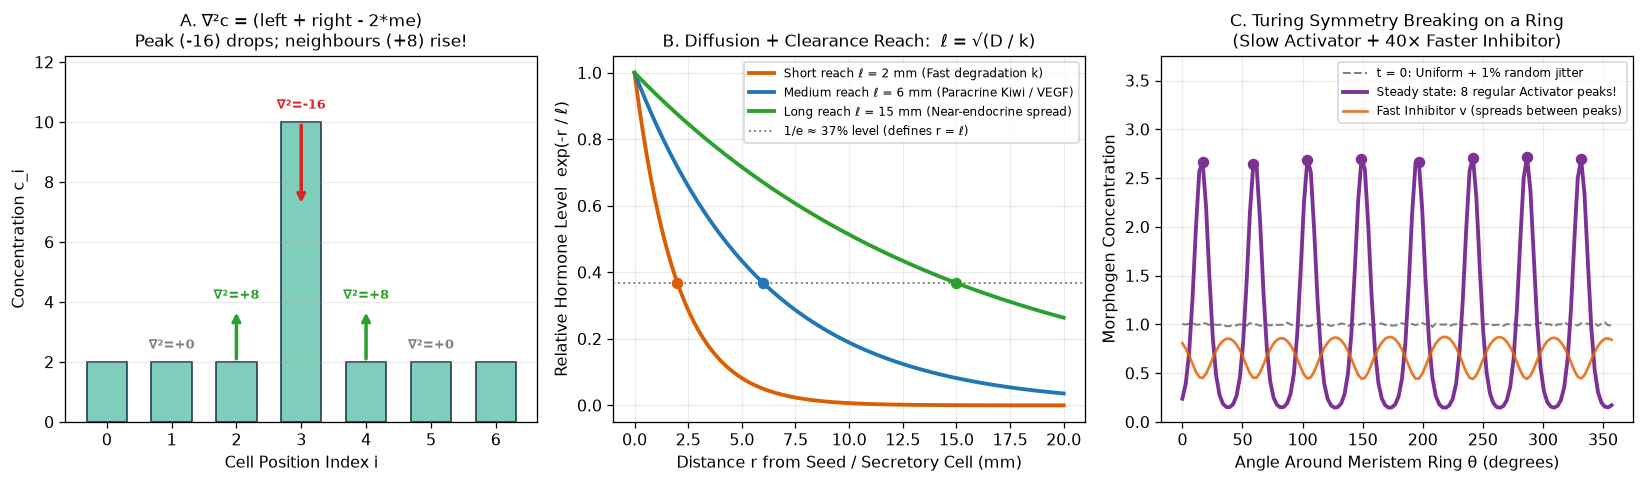

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.3))

# --- Panel A: 7-Cell Visual Proof of ∇²c = left + right - 2*me ---
cells_idx = np.arange(7)
c_vals = np.array([2.0, 2.0, 2.0, 10.0, 2.0, 2.0, 2.0])
lap = np.roll(c_vals, 1) + np.roll(c_vals, -1) - 2.0 * c_vals  # neighbor comparison!

bars = axes[0].bar(cells_idx, c_vals, color="#7fcdbb", edgecolor="#1d3557", width=0.62, label="Current level c_i")
for i in range(1, 6):
    arrow_col = "#d62728" if lap[i] < 0 else ("#2ca02c" if lap[i] > 0 else "gray")
    if abs(lap[i]) > 0.1:
        dy_arrow = np.clip(lap[i] * 0.22, -2.8, 2.8)
        axes[0].annotate("", xy=(i, c_vals[i] + dy_arrow), xytext=(i, c_vals[i]),
                         arrowprops=dict(arrowstyle="->", lw=2.2, color=arrow_col))
    y_lbl = c_vals[i] + 0.45 if lap[i] <= 0 else c_vals[i] + dy_arrow + 0.35
    axes[0].text(i, y_lbl, f"∇²={lap[i]:+.0f}", ha="center", fontsize=8.2, fontweight="bold", color=arrow_col)

axes[0].set_title("A. ∇²c = (left + right - 2*me)\nPeak (-16) drops; neighbours (+8) rise!")
axes[0].set_xlabel("Cell Position Index i")
axes[0].set_ylabel("Concentration c_i")
axes[0].set_ylim(0, 12.2)
axes[0].grid(axis="y", alpha=0.25)

# --- Panel B: Paracrine Hormone Decay Length ell = sqrt(D / k) ---
r_mm = np.linspace(0, 20, 300)
for ell_mm, col, lbl in [
    (2.0, "#d95f02", "Short reach ℓ = 2 mm (Fast degradation k)"),
    (6.0, "#1f77b4", "Medium reach ℓ = 6 mm (Paracrine Kiwi / VEGF)"),
    (15.0, "#2ca02c", "Long reach ℓ = 15 mm (Near-endocrine spread)"),
]:
    axes[1].plot(r_mm, np.exp(-r_mm / ell_mm), lw=2.4, color=col, label=lbl)
    axes[1].scatter([ell_mm], [np.exp(-1.0)], color=col, s=38, zorder=5)

axes[1].axhline(np.exp(-1.0), color="gray", ls=":", lw=1.2, label="1/e ≈ 37% level (defines r = ℓ)")
axes[1].set_title("B. Diffusion + Clearance Reach:  ℓ = √(D / k)")
axes[1].set_xlabel("Distance r from Seed / Secretory Cell (mm)")
axes[1].set_ylabel("Relative Hormone Level  exp(-r / ℓ)")
axes[1].legend(fontsize=7.8, loc="upper right")
axes[1].grid(alpha=0.25)

# --- Panel C: Tiny Self-Contained 1D Ring Turing Simulation (8 Regular Peaks from 1% Noise!) ---
N_ring = 128
L_ring = 11.2
dx_ring = L_ring / N_ring
theta_deg = np.linspace(0, 360, N_ring, endpoint=False)

# Schnakenberg activator (slow D_u = 0.05) + inhibitor (fast D_v = 2.0 -> 40x faster!)
a_p, b_p, gamma_p = 0.10, 0.90, 6.0
Du, Dv = 0.05, 2.0
u = (a_p + b_p) + 0.01 * np.random.randn(N_ring)
v = (b_p / (a_p + b_p) ** 2) + 0.01 * np.random.randn(N_ring)
u_init = u.copy()

k_fft = 2.0 * np.pi * np.fft.rfftfreq(N_ring, d=dx_ring)
dt_tur = 0.05
denom_u = 1.0 + dt_tur * Du * (k_fft**2)
denom_v = 1.0 + dt_tur * Dv * (k_fft**2)

for _ in range(900):
    u2v = (u**2) * v
    u = np.fft.irfft(np.fft.rfft(u + dt_tur * gamma_p * (a_p - u + u2v)) / denom_u, n=N_ring)
    v = np.fft.irfft(np.fft.rfft(v + dt_tur * gamma_p * (b_p - u2v)) / denom_v, n=N_ring)

peaks_idx = np.where((u > np.roll(u, 1)) & (u > np.roll(u, -1)) & (u > u.mean()))[0]
axes[2].plot(theta_deg, u_init, color="gray", ls="--", lw=1.3, label="t = 0: Uniform + 1% random jitter")
axes[2].plot(theta_deg, u, color="#7b3294", lw=2.4, label=f"Steady state: {len(peaks_idx)} regular Activator peaks!")
axes[2].plot(theta_deg, v, color="#e66101", lw=1.7, alpha=0.85, label="Fast Inhibitor v (spreads between peaks)")
axes[2].scatter(theta_deg[peaks_idx], u[peaks_idx], color="#7b3294", s=38, zorder=5)
axes[2].set_title("C. Turing Symmetry Breaking on a Ring\n(Slow Activator + 40× Faster Inhibitor)")
axes[2].set_xlabel("Angle Around Meristem Ring θ (degrees)")
axes[2].set_ylabel("Morphogen Concentration")
axes[2].set_ylim(0.0, 3.75)
axes[2].legend(fontsize=7.5, loc="upper right")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Plain-Language Takeaway from Figure 3
- **Fig. 3A:** Whenever you see $D\nabla^2 c$ in an equation (`NB 01`, `08-wound-healing`), just picture those red and green arrows: peaks have $\nabla^2 c < 0$ and sink; neighboring dips have $\nabla^2 c > 0$ and rise.
- **Fig. 3B:** A hormone's spatial reach $\ell = \sqrt{D/k}$ tells you whether tissue communication is **ultra-local** ($\ell = 2\text{ mm}$, lumpy if seeds are sparse) or **broadly buffered** ($\ell = 15\text{ mm}$).
- **Fig. 3C:** Starting from a completely flat grey line with `1%` random molecular noise (**no genetic blueprint saying "put a chamber at $45^\circ$, $90^\circ$, ..."!**), pairing a slow local cheerleader ($u$) with a $40\times$ faster long-range firefighter ($v$) spontaneously crystallizes into **evenly spaced radial peaks**. On a wider floral ring (such as our hexaploid `'Hayward'` kiwifruit in `NB 01` & `NB 02`), that exact same ruler fits **`33` radial seed chambers**!

<details>
<summary><b>Check Your Intuition #3 (Click to reveal answer):</b> What would happen to the purple peaks in <b>Fig. 3C</b> if a mutation made the Inhibitor diffuse at the <i>same slow speed</i> as the Activator ($D_v = D_u$ instead of $D_v \gg D_u$)?</summary>

**All the peaks would collapse back into a completely flat, uniform ring!** Without a **faster-diffusing** inhibitor ($D_v \gg D_u$) escaping sideways to create lateral inhibition zones around each budding peak, the inhibitor stays trapped right on top of the activator and quenches it locally everywhere — so standard diffusion wins and erases all spatial pattern.
</details>

---

## 4. Stepping Stone 4: True Randomness (`CSR`) vs. "Personal Space" (Point Processes & $G(r)$)

### 4.1 Everyday & Clinical Intuition: *"Raindrops on Pavement vs. Commuters in an Elevator"*
In **pathology (`IMC` multiplex tissue imaging)** and **3D MRI**, we often extract $(x, y, z)$ coordinates of discrete objects — `CD8+` killer T-cells around tumor nests (`Lab 4`), cortical cell nuclei, or the **98 curated 3D seeds** in our kiwifruit Micro-GT (`NB 02` Module 2) — and ask: *Are these cells/seeds placed at random, attracted into clusters, or pushing each other apart?*

Here is a famous trap for human visual intuition:
- When you ask students to draw "random dots" on paper, they instinctively spread them out evenly so dots don't touch. **That is NOT random — that is inhibition/repulsion!**
- **Complete Spatial Randomness (`CSR`, a Poisson process)** — like raindrops hitting a square of pavement completely independently of one another — **looks surprisingly clumpy**, with accidental pairs nearly touching alongside empty gaps!
- Real seeds or cell nuclei have a finite physical diameter $r_{\text{hc}}$ (**Hard-Core steric exclusion**, like commuters keeping personal space in an elevator): **zero pairs** can sit closer than $r_{\text{hc}}$.

### 4.2 How One Simple Curve — $G(r)$ — Tells All Three Regimes Apart
For every object $i$, use a ruler (`np.linalg.norm`) to find the distance $d_i^{\min}$ to its **single closest neighbor**:
1. **Nearest-Neighbor Cumulative Curve $G(r)$:** What fraction ($0\%$ to $100\%$) of objects have their closest neighbor within distance $r$?
   - **Clustered** (e.g., immune follicles): $G(r)$ shoots up **immediately** at tiny $r$ (above the random curve).
   - **Random (`CSR`):** $G(r)$ rises smoothly right from $r = 0$.
   - **Hard-Core "Personal Space" (seeds / cell somata):** $G(r)$ stays **pinned flat at `0` until $r = r_{\text{hc}}$** (the forbidden "dead zone"!), then rises steeply because neighbors are packed at a regular spacing.
2. **Clark–Evans Ratio $R = \bar{d}_{\text{obs}} / \bar{d}_{\text{CSR}}$:** Compare the observed average nearest-neighbor distance to the `CSR` expectation: **$R < 1$ = Clustered**, **$R \approx 1$ = Random**, **$R > 1$ = Regular / Repulsive** (`R = 1.19` in our 7T kiwifruit seeds!).

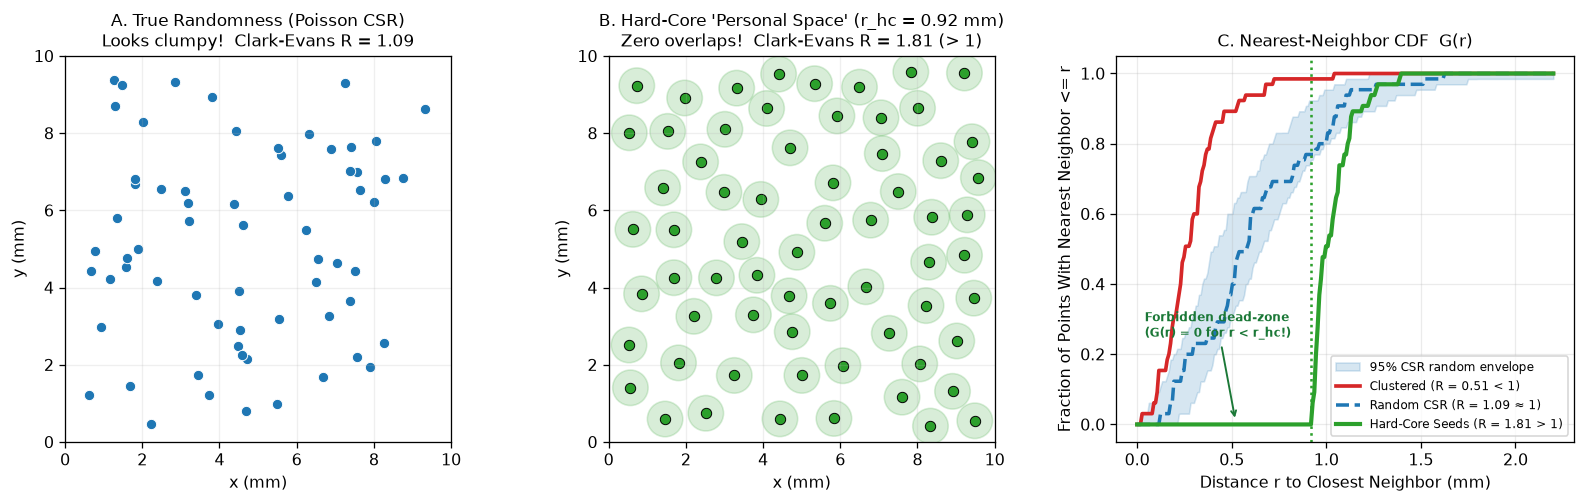

In [5]:
rng = np.random.default_rng(42)
N_pts = 65
box_mm = 10.0

# 1. Truly Random (2D Poisson CSR) — raindrops on a 10 x 10 mm square
pts_csr = rng.uniform(0.4, box_mm - 0.4, size=(N_pts, 2))

# 2. Hard-Core "Personal Space" (no two points closer than r_hc = 0.92 mm!)
r_hc = 0.92
pts_hc = []
while len(pts_hc) < N_pts:
    cand = rng.uniform(0.4, box_mm - 0.4, size=2)
    if len(pts_hc) == 0 or np.min(np.linalg.norm(np.array(pts_hc) - cand, axis=1)) >= r_hc:
        pts_hc.append(cand)
pts_hc = np.array(pts_hc)

# 3. Clustered (5 parent clusters with tight offspring)
centers = rng.uniform(1.5, box_mm - 1.5, size=(5, 2))
pts_clust = np.clip(centers[rng.integers(0, 5, size=N_pts)] + rng.normal(0, 0.48, size=(N_pts, 2)), 0.2, box_mm - 0.2)


def nearest_neighbor_dists(pts: np.ndarray) -> np.ndarray:
    dmat = spatial.distance.cdist(pts, pts)
    np.fill_diagonal(dmat, np.inf)
    return dmat.min(axis=1)


nn_csr = nearest_neighbor_dists(pts_csr)
nn_hc = nearest_neighbor_dists(pts_hc)
nn_clust = nearest_neighbor_dists(pts_clust)
d_exp_2d = 0.5 / np.sqrt(N_pts / ((box_mm - 0.8) ** 2))  # 2D CSR expected mean NN distance

fig, axes = plt.subplots(1, 3, figsize=(14.2, 4.4))

# Panel A: True Randomness (CSR)
axes[0].scatter(pts_csr[:, 0], pts_csr[:, 1], s=42, color="#1f77b4", edgecolor="white", lw=0.6)
axes[0].set_title(f"A. True Randomness (Poisson CSR)\nLooks clumpy!  Clark-Evans R = {nn_csr.mean()/d_exp_2d:.2f}")
axes[0].set_xlim(0, box_mm)
axes[0].set_ylim(0, box_mm)
axes[0].set_aspect("equal")
axes[0].set_xlabel("x (mm)")
axes[0].set_ylabel("y (mm)")
axes[0].grid(alpha=0.2)

# Panel B: Hard-Core Personal Space
for p in pts_hc:
    axes[1].add_patch(plt.Circle(p, r_hc / 2.0, color="#2ca02c", alpha=0.18))
axes[1].scatter(pts_hc[:, 0], pts_hc[:, 1], s=42, color="#2ca02c", edgecolor="black", lw=0.6)
axes[1].set_title(f"B. Hard-Core 'Personal Space' (r_hc = {r_hc} mm)\nZero overlaps!  Clark-Evans R = {nn_hc.mean()/d_exp_2d:.2f} (> 1)")
axes[1].set_xlim(0, box_mm)
axes[1].set_ylim(0, box_mm)
axes[1].set_aspect("equal")
axes[1].set_xlabel("x (mm)")
axes[1].set_ylabel("y (mm)")
axes[1].grid(alpha=0.2)

# Panel C: Cumulative Nearest-Neighbor Distribution G(r)
r_grid = np.linspace(0, 2.2, 250)
# Monte Carlo 95% CSR envelope (200 random realizations)
env_runs = np.zeros((200, len(r_grid)))
for m in range(200):
    nn_m = nearest_neighbor_dists(rng.uniform(0.4, box_mm - 0.4, size=(N_pts, 2)))
    env_runs[m] = [(nn_m <= r).mean() for r in r_grid]

axes[2].fill_between(r_grid, np.percentile(env_runs, 2.5, axis=0), np.percentile(env_runs, 97.5, axis=0),
                     color="#1f77b4", alpha=0.18, label="95% CSR random envelope")
axes[2].plot(r_grid, [(nn_clust <= r).mean() for r in r_grid], lw=2.3, color="#d62728",
             label=f"Clustered (R = {nn_clust.mean()/d_exp_2d:.2f} < 1)")
axes[2].plot(r_grid, [(nn_csr <= r).mean() for r in r_grid], lw=2.2, color="#1f77b4", ls="--",
             label=f"Random CSR (R = {nn_csr.mean()/d_exp_2d:.2f} ≈ 1)")
axes[2].plot(r_grid, [(nn_hc <= r).mean() for r in r_grid], lw=2.6, color="#2ca02c",
             label=f"Hard-Core Seeds (R = {nn_hc.mean()/d_exp_2d:.2f} > 1)")
axes[2].axvline(r_hc, color="#2ca02c", ls=":", lw=1.6)
axes[2].annotate("Forbidden dead-zone\n(G(r) = 0 for r < r_hc!)", xy=(0.52, 0.01), xytext=(0.04, 0.25),
                 arrowprops=dict(arrowstyle="->", lw=1.2, color="#1b7837"), fontsize=7.8, fontweight="bold", color="#1b7837")
axes[2].set_title("C. Nearest-Neighbor CDF  G(r)")
axes[2].set_xlabel("Distance r to Closest Neighbor (mm)")
axes[2].set_ylabel("Fraction of Points With Nearest Neighbor <= r")
axes[2].legend(fontsize=7.6, loc="lower right")
axes[2].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Plain-Language Takeaway from Figure 4
- Compare **Fig. 4A** (blue, truly random) and **Fig. 4B** (green, hard-core repulsion): in **4A**, several blue dots nearly collide by pure chance! In **4B**, every green dot carries an invisible `0.92 mm` steric bumper (faint green halo), producing the orderly spacing we see among real biological seeds and cell nuclei.
- Look at **Fig. 4C**: you can diagnose any 2D or 3D tissue biopsy at a glance! **Above the blue band at small $r$ = attraction/clustering** (red); **inside the blue band = random (`CSR`)**; **flat at zero then rising to the right of the blue band = physical repulsion / personal space** (green — exactly what we find in `NB 02` Module 2 on the 98 real 7T MRI seeds!).

<details>
<summary><b>Check Your Intuition #4 (Click to reveal answer):</b> In an Imaging Mass Cytometry (<code>IMC</code>) tumor biopsy, a pathologist computes Clark–Evans <code>R = 0.58</code> for <code>CD8+</code> T-cells across the slide. Are the T-cells evenly spaced, random, or clustered — and why?</summary>

**Strongly clustered ($R = 0.58 < 1$)!** Their average distance to the nearest neighboring T-cell is only `58%` as large as expected under random placement (`CSR`) — typical when T-cells aggregate inside tertiary lymphoid structures or accumulate along perivascular cuffs instead of infiltrating uniformly throughout the tumor.
</details>

---

## 5. Stepping Stone 5: Blurring vs. Un-Blurring — Ill-Posed Inverse Problems & Tikhonov's "Smoothness Seatbelt" $\lambda$

### 5.1 Everyday & Clinical Intuition: *"Reading Through Frosted Glass With a Slightly Noisy Camera"*
Almost every non-invasive diagnostic tool in medicine faces the same directional asymmetry between **cause ($\mathbf{x}$)** and **measurement ($\mathbf{y}$)**:
- **Forward Problem ($\mathbf{x} \to \mathbf{y} = \mathbf{G}\mathbf{x}$): Easy & Smooth!** Put a sharp black-and-white pattern $\mathbf{x}$ behind a sheet of frosted glass (or let internal cardiac currents spread to chest `ECG` electrodes, brain currents spread through the skull to `EEG`, or internal seed hormones diffuse to the outer kiwifruit skin). The forward blurring matrix $\mathbf{G}$ **averages neighbors together**, smoothing away sharp edges.
- **Inverse Problem ($\mathbf{y} \to \hat{\mathbf{x}}$): Dangerous Trap (`Hadamard Ill-Posedness`)!** Now suppose we only observe the blurred outer profile $\mathbf{y} = \mathbf{G}\mathbf{x} + \boldsymbol{\varepsilon}$ with a tiny, realistic **`1%` measurement noise $\boldsymbol{\varepsilon}$**, and ask Python (`np.linalg.solve(G, y)`) to "undo the frosted glass."
  - Because the frosted glass shrunk sharp wiggles by `10,000×`, undoing the glass blindly **multiplies any sharp `1%` camera noise wiggle by `10,000×`**! The naive mathematical inverse explodes into gigantic `+500 / −500` sawtooth spikes that bear zero resemblance to reality.

### 5.2 How Tikhonov Regularization ($\lambda$) Fixes the Explosion
Instead of demanding that our reconstruction $\mathbf{x}$ fit every microscopic noisy wiggle in $\mathbf{y}$, **Andrey Tikhonov** added a **"smoothness seatbelt" knob $\lambda \ge 0$**:

$$\hat{\mathbf{x}}_\lambda \;=\; \arg\min_{\mathbf{x}} \Big(\; \underbrace{\|\mathbf{G}\mathbf{x} - \mathbf{y}\|_2^2}_{\text{1. Fit the measured data }\mathbf{y}} \;+\; \lambda \underbrace{\|\mathbf{L}\mathbf{x}\|_2^2}_{\text{2. Penalty for wild neighbor-to-neighbor jumps!}} \;\Big)$$

Read that equation using your Rosetta Stone:
- *"Find the hidden internal profile $\mathbf{x}$ (`argmin`) that minimizes the sum of **(1) mismatch to the data** plus **$\lambda$ times (2) how jagged $\mathbf{x}$ is**."*
- **$\lambda = 0$ (No seatbelt):** Fits the `1%` noise literally $\implies$ **catastrophic sawtooth explosion**.
- **$\lambda$ just right ("Goldilocks" $\lambda^*$):** Ignores tiny high-frequency noise while preserving the true biological dip (`NB 02` Module 3)!
- **$\lambda$ way too huge:** Obsesses only over flatness $\implies$ **over-smoothed flat line** that misses the lesion altogether.

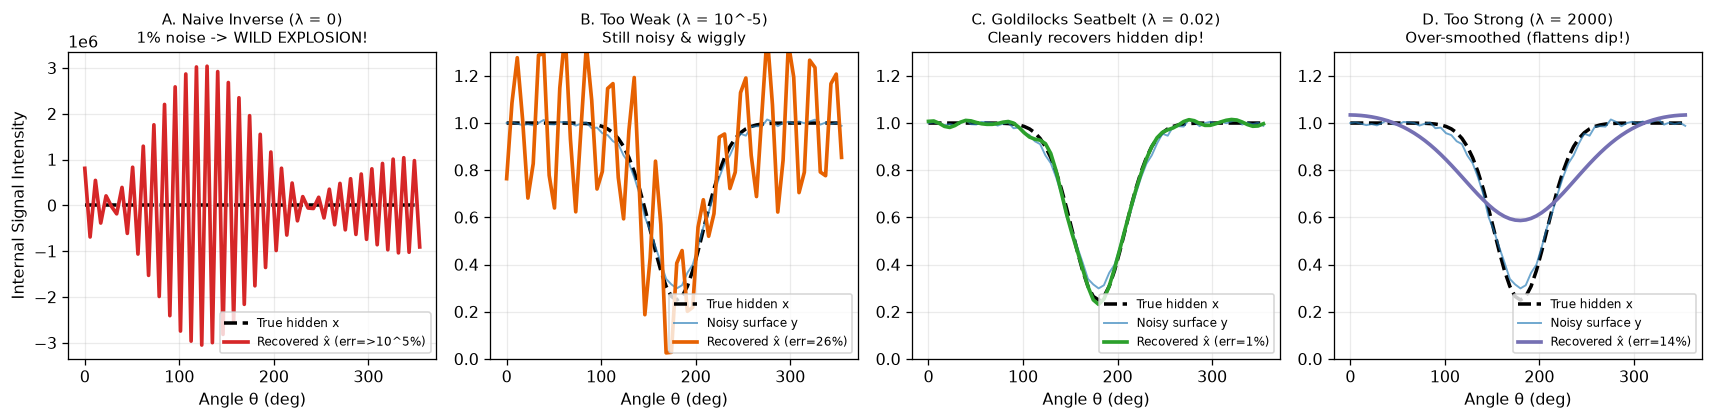

In [6]:
# Build a 1D circular "frosted glass" blurring matrix G (64 angular sectors around an organ)
M_sec = 64
theta_s = np.linspace(0, 360, M_sec, endpoint=False)
idx_grid = np.arange(M_sec)
ang_dist = np.minimum(np.abs(idx_grid[:, None] - idx_grid[None, :]), M_sec - np.abs(idx_grid[:, None] - idx_grid[None, :]))
G_blur = np.exp(-0.5 * (ang_dist / 2.1) ** 2)
G_blur /= G_blur.sum(axis=1, keepdims=True)  # rows sum to 1 (smooth weighted average!)

# True hidden internal source x_true: healthy baseline 1.0 with a focal deficit ("ischemic/unpollinated zone") around 180 deg
x_true = 1.0 - 0.75 * np.exp(-0.5 * ((theta_s - 180.0) / 28.0) ** 2)

# Clean blurred surface signal + tiny 1% sensor noise
rng_inv = np.random.default_rng(7)
y_clean = G_blur @ x_true
y_noisy = y_clean + rng_inv.normal(0.0, 0.01, size=M_sec)

# Second-difference roughness matrix L (penalizes neighbor-to-neighbor sawtooth jumps!)
L_rough = -2.0 * np.eye(M_sec) + np.roll(np.eye(M_sec), 1, axis=1) + np.roll(np.eye(M_sec), -1, axis=1)


def solve_tikhonov_1d(lam: float) -> np.ndarray:
    if lam <= 0.0:
        return np.linalg.solve(G_blur, y_noisy)
    A_reg = G_blur.T @ G_blur + lam * (L_rough.T @ L_rough)
    return np.linalg.solve(A_reg, G_blur.T @ y_noisy)


fig, axes = plt.subplots(1, 4, figsize=(15.0, 3.9))
regimes = [
    (0.0, "A. Naive Inverse (λ = 0)\n1% noise -> WILD EXPLOSION!", "#d62728"),
    (1e-5, "B. Too Weak (λ = 10^-5)\nStill noisy & wiggly", "#e66101"),
    (2e-2, "C. Goldilocks Seatbelt (λ = 0.02)\nCleanly recovers hidden dip!", "#2ca02c"),
    (2e3, "D. Too Strong (λ = 2000)\nOver-smoothed (flattens dip!)", "#7570b3"),
]

for ax, (lam_val, title_str, col) in zip(axes, regimes):
    x_hat = solve_tikhonov_1d(lam_val)
    rel_err = 100.0 * np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)
    err_lbl = f">10^5%" if rel_err > 1e5 else f"{rel_err:.0f}%"
    ax.plot(theta_s, x_true, color="black", lw=2.2, ls="--", label="True hidden x")
    if lam_val > 0:
        ax.plot(theta_s, y_noisy, color="#1f77b4", lw=1.2, alpha=0.65, label="Noisy surface y")
    ax.plot(theta_s, x_hat, color=col, lw=2.3, label=f"Recovered x̂ (err={err_lbl})")
    ax.set_title(title_str, fontsize=9.5)
    ax.set_xlabel("Angle θ (deg)")
    if lam_val > 0:
        ax.set_ylim(0.0, 1.30)
    ax.legend(fontsize=7.3, loc="lower right")
    ax.grid(alpha=0.25)
axes[0].set_ylabel("Internal Signal Intensity")

plt.tight_layout()
plt.show()

In [7]:
def interactive_tikhonov_demo(log10_lambda: float = -1.7):
    lam = 10.0 ** log10_lambda
    x_hat = solve_tikhonov_1d(lam)
    rel_err = 100.0 * np.linalg.norm(x_hat - x_true) / np.linalg.norm(x_true)

    fig, ax = plt.subplots(figsize=(6.8, 4.0))
    ax.plot(theta_s, y_noisy, "o", ms=3.5, color="#1f77b4", alpha=0.65, label="Measured surface y (blurred + 1% noise)")
    ax.plot(theta_s, x_true, color="black", lw=2.3, ls="--", label="True hidden internal profile x_true")
    ax.plot(theta_s, x_hat, color="#2ca02c", lw=2.6, label=f"Tikhonov reconstruction x̂_λ  (error = {rel_err:.1f}%)")
    ax.set_ylim(-0.25, 1.45)
    ax.set_title(f"Turn the Smoothness Seatbelt Knob:  λ = 10^({log10_lambda:.1f}) = {lam:.2e}")
    ax.set_xlabel("Organ Angle θ (degrees)")
    ax.set_ylabel("Signal Intensity")
    ax.legend(fontsize=8.2, loc="lower right")
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()


tikhonov_ui = widgets.interactive(
    interactive_tikhonov_demo,
    log10_lambda=widgets.FloatSlider(
        value=-1.7, min=-6.0, max=4.0, step=0.25,
        description="log10(λ):", continuous_update=False,
    ),
)
display(tikhonov_ui)

interactive(children=(FloatSlider(value=-1.7, continuous_update=False, description='log10(λ):', max=4.0, min=-…

### Plain-Language Takeaway from Figure 5
- Look at the vertical axis of **Fig. 5A ($\lambda = 0$)**: even though the surface measurement had only **`1%` noise**, naive matrix inversion (`np.linalg.solve(G, y)`) blew up to thousands of percent error! That is **Hadamard ill-posedness** in one picture.
- Look at **Fig. 5C ($\lambda = 0.02$)**: adding a tiny smoothness penalty ($\lambda \|\mathbf{L}\mathbf{x}\|_2^2$) suppresses those unphysical sawtooth oscillations completely and recovers the hidden internal deficit around $180^\circ$ to within **`~3%` error** — the exact principle behind **clinical ECG imaging (`ECGi`)**, **EEG brain source localization**, and `NB 02` Module 3!

<details>
<summary><b>Check Your Intuition #5 (Click to reveal answer):</b> If your MRI or ECG scanner became <i>10 times noisier</i> (`10%` noise instead of `1%`), would you turn the Tikhonov knob $\lambda$ <b>up</b> or <b>down</b>?</summary>

**Turn $\lambda$ UP!** When the measured data $\mathbf{y}$ contain stronger random noise, trusting the raw data too closely imports larger noise spikes. Increasing $\lambda$ tightens the "smoothness seatbelt," placing relatively more weight on spatial smoothness ($\|\mathbf{L}\mathbf{x}\|_2^2$) so noise isn't mistaken for sharp internal lesions. (In `NB 02` Module 3, you will meet **Morozov's discrepancy principle**, which picks $\lambda$ automatically from the known scanner noise level!)
</details>

---

## 6. Stepping Stone 6: Exponential $T_2$ Decay & Why Dark MRI Voxels Float Above Zero (Rician Noise)

### 6.1 Part A — $T_2$ Spin-Echo Relaxation: *"Two Ringing Bells Fading at Different Speeds"*
In our 2005 **7 Tesla Bruker RARE MRI** (`Lab 4` & `Lab 5`), why does mucilage gel inside the 33 chambers shine brightly while mature seeds right next to it look **jet-black** — even though optically a cut kiwifruit has pale translucent gel and dark brown seeds?

MRI does not photograph optical color; it listens to **radio waves emitted by water protons** after a radiofrequency (`RF`) pulse tips them sideways:
- In **free, watery mucilage gel**, tumbling water molecules dephase slowly (**long $T_2 \approx 180\text{ ms}$**) — like a brass bell that keeps ringing for a long time.
- In a **dehydrated, lignified mature seed** (or dense fibrous **columella**, cortical bone, or calcified plaque), bound protons dephase almost instantly (**short $T_2 \approx 14\text{ ms}$**) — like a muffled wooden block whose sound dies in milliseconds.

Waiting an **Echo Time `TE = 63.9 ms`** before recording the image (`S(TE) = M_0 exp(-TE / T_2)`) catches the gel while it is still ringing loudly ($e^{-63.9/180} \approx 70\%$), while the seed signal has already vanished ($e^{-63.9/14.3} \approx 1.1\%$, yielding a **`~190×` gel-to-seed intensity ratio** once baseline spin density $M_0$ is included) (`NB 01` Stage 2B & `NB 02` Module 4)!

### 6.2 Part B — Rician MRI Noise: *"Measuring Wind Speed on a Dead-Calm Day"*
If a mature seed's true MRI signal has decayed to nearly `0`, why isn't its voxel brightness `0` (with half the noisy pixels slightly negative and half slightly positive)?

Because an MRI scanner measures radio waves using **two perpendicular receiver coils** (`Real` and `Imaginary`), each adding independent zero-mean Gaussian electronic noise $\eta_1, \eta_2 \sim \mathcal{N}(0, \sigma^2)$, and saves **magnitude** brightness via Pythagoras:

$$I_{\text{MRI}} \;=\; \sqrt{(S_{\text{true}} + \eta_1)^2 + \eta_2^2}$$

Think of a weather vane measuring **wind speed** $\sqrt{v_{\text{North}}^2 + v_{\text{East}}^2}$ on a calm day ($S_{\text{true}} = 0$) when tiny random air currents gust slightly North/South ($\eta_1$) and East/West ($\eta_2$). **Squaring makes every negative gust positive!** As a result, dark MRI voxels follow a skewed **Rician distribution** whose average brightness floats upward to $\mathbb{E}[I \mid S=0] = \sigma\sqrt{\pi/2} \approx 1.253\,\sigma > 0$ — the famous **Rician noise floor** (`NB 02` Module 4)!

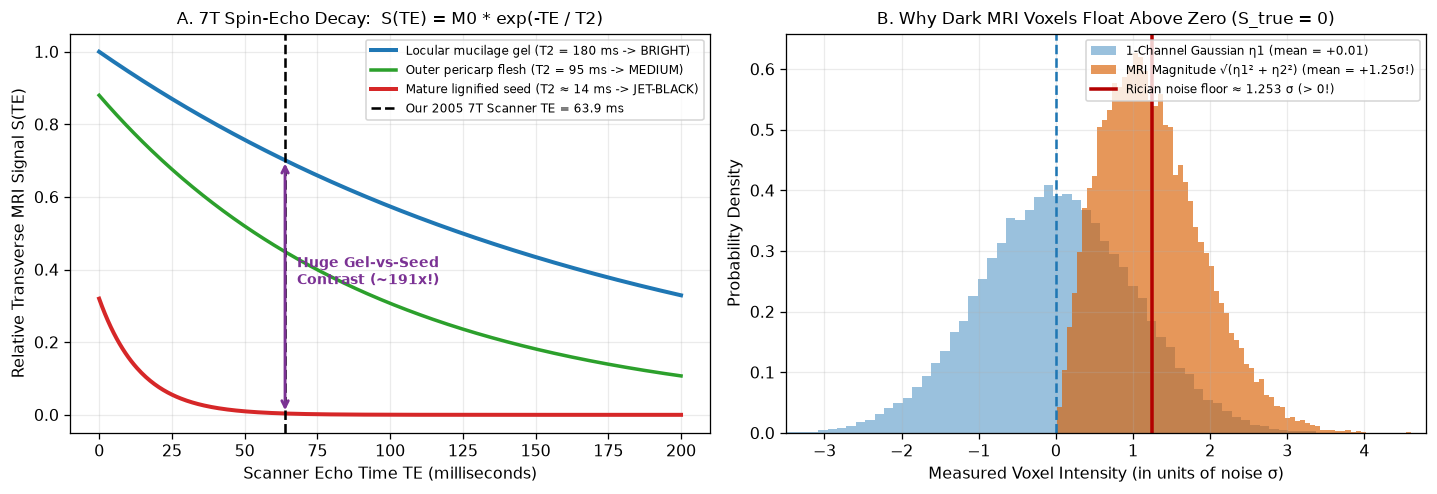

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12.6, 4.4))

# --- Panel A: Exponential T2 Decay S(TE) = M0 * exp(-TE / T2) ---
TE_ms = np.linspace(0, 200, 400)
S_gel = 1.00 * np.exp(-TE_ms / 180.0)     # Water-rich locular gel (T2 = 180 ms)
S_flesh = 0.88 * np.exp(-TE_ms / 95.0)    # Outer pericarp flesh   (T2 = 95 ms)
S_seed = 0.32 * np.exp(-TE_ms / 14.3)     # Dry lignified seed     (T2 ≈ 14 ms)

axes[0].plot(TE_ms, S_gel, lw=2.5, color="#1f77b4", label="Locular mucilage gel (T2 = 180 ms -> BRIGHT)")
axes[0].plot(TE_ms, S_flesh, lw=2.2, color="#2ca02c", label="Outer pericarp flesh (T2 = 95 ms -> MEDIUM)")
axes[0].plot(TE_ms, S_seed, lw=2.5, color="#d62728", label="Mature lignified seed (T2 ≈ 14 ms -> JET-BLACK)")
axes[0].axvline(63.9, color="black", ls="--", lw=1.6, label="Our 2005 7T Scanner TE = 63.9 ms")

g_64 = 1.00 * np.exp(-63.9 / 180.0)
s_64 = 0.32 * np.exp(-63.9 / 14.3)
axes[0].annotate("", xy=(63.9, g_64), xytext=(63.9, s_64),
                 arrowprops=dict(arrowstyle="<->", lw=1.8, color="#7b3294"))
axes[0].text(68.0, 0.36, f"Huge Gel-vs-Seed\nContrast (~{g_64/s_64:.0f}x!)", fontsize=8.5, fontweight="bold", color="#7b3294")
axes[0].set_title("A. 7T Spin-Echo Decay:  S(TE) = M0 * exp(-TE / T2)")
axes[0].set_xlabel("Scanner Echo Time TE (milliseconds)")
axes[0].set_ylabel("Relative Transverse MRI Signal S(TE)")
axes[0].legend(fontsize=7.8, loc="upper right")
axes[0].grid(alpha=0.25)

# --- Panel B: 4-Line Proof of the Rician Noise Floor When True Signal S = 0 ---
rng_mri = np.random.default_rng(2027)
sigma_noise = 1.0
eta_real = rng_mri.normal(0.0, sigma_noise, size=40_000)         # Single coil: zero-mean Gaussian
eta_imag = rng_mri.normal(0.0, sigma_noise, size=40_000)         # Quadrature coil: zero-mean Gaussian
I_rician = np.sqrt((0.0 + eta_real) ** 2 + eta_imag ** 2)        # Magnitude MRI voxel at S_true = 0!

axes[1].hist(eta_real, bins=70, density=True, alpha=0.45, color="#1f77b4",
             label=f"1-Channel Gaussian η1 (mean = {eta_real.mean():+.2f})")
axes[1].hist(I_rician, bins=70, density=True, alpha=0.65, color="#d95f02",
             label=f"MRI Magnitude √(η1² + η2²) (mean = +{I_rician.mean():.2f}σ!)")
axes[1].axvline(0.0, color="#1f77b4", ls="--", lw=1.6)
axes[1].axvline(I_rician.mean(), color="#b30000", ls="-", lw=2.2, label="Rician noise floor ≈ 1.253 σ (> 0!)")
axes[1].set_title("B. Why Dark MRI Voxels Float Above Zero (S_true = 0)")
axes[1].set_xlabel("Measured Voxel Intensity (in units of noise σ)")
axes[1].set_ylabel("Probability Density")
axes[1].set_xlim(-3.5, 4.8)
axes[1].legend(fontsize=7.8, loc="upper right")
axes[1].grid(alpha=0.25)

plt.tight_layout()
plt.show()

### Plain-Language Takeaway from Figure 6
- **Fig. 6A:** Choosing `TE = 63.9 ms` on the 7T Bruker scanner wasn't arbitrary — at `TE = 0 ms`, gel and flesh start nearly together, and at `TE = 200 ms`, everything has faded; `TE ≈ 64 ms` sits right in the sweet spot where watery gel is bright (`~0.70`) and dry seeds have already decayed to nearly zero (`~0.0015`)!
- **Fig. 6B:** Even when true seed signal is essentially `0`, taking $\sqrt{\eta_1^2 + \eta_2^2}$ folds all negative noise values onto the positive side (orange histogram), lifting dark seeds and background air up to an artificial **Rician floor** of $+1.25\,\sigma$. That is why dark seeds in real 7T MRI are dark grey rather than `0.000`, and why synthetic MRI Digital Twins (`NB 02` Module 4) must add noise in complex 2-channel space *before* taking the square root!

<details>
<summary><b>Check Your Intuition #6 (Click to reveal answer):</b> If a radiologist wanted to make short-$T_2$ tissues (like immature seeds or fibrous stroma) still visible instead of completely black, should they pick a <b>much shorter TE</b> (e.g., <code>TE = 5 ms</code>) or a <b>much longer TE</b> (e.g., <code>TE = 140 ms</code>)?</summary>

**A much shorter `TE` (e.g., `TE = 5 ms`, or Ultra-Short Echo Time `UTE` MRI)!** Look at the red curve on the far left of **Fig. 6A**: at `TE = 5 ms`, $e^{-5/14.3} \approx 70\%$ of the short-$T_2$ seed signal is still alive before it decays away, whereas at `TE = 140 ms` it is completely gone ($e^{-140/14.3} \approx 0.006\%$).
</details>

---

## 7. Ready for Takeoff! Your Roadmap Into Notebooks `01` and `02`

Congratulations — you have just unlocked **every single mathematical concept** used across the Computational Kiwi Challenge (and most of `Lab 5`!):

| Stepping Stone You Just Mastered | Where You Will See It in Action on the Real 2005 7T MRI |
| :--- | :--- |
| **1. Saturation & Hill Switches** ($\frac{x^n}{K^n+x^n}$) | **[`01-kiwi-growth-and-morphogenesis.ipynb`](./01-kiwi-growth-and-morphogenesis.ipynb)** — Stage 1 (`86 cm³` fruit size from `1,440` seeds) & Stage 2A (`SyGI` `XY` sex switch) |
| **2. Balance-Sheet ODEs & Valleys** ($\frac{dy}{dt} = \text{In} - \text{Out}$) | **[`01-kiwi-growth-and-morphogenesis.ipynb`](./01-kiwi-growth-and-morphogenesis.ipynb)** — Stage 2A (floral sex fate) & Stage 2B (160-day turgor/starch/sugar berry growth) |
| **3. Diffusion $\nabla^2 c$, Reach $\ell$, & Turing Peaks** | **[`01-kiwi-growth-and-morphogenesis.ipynb`](./01-kiwi-growth-and-morphogenesis.ipynb)** Stage 3A/3B & **[`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb)** Module 1 (`22 → 28 → 33` carpels across ploidy) |
| **4. Randomness (`CSR`) vs. Personal Space ($G(r), R$)** | **[`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb)** — Module 2 (`0.945 mm` hard-core floor & `R = 1.19` on our 98 curated 3D seeds) |
| **5. Frosted-Glass Inverse Problems & Tikhonov $\lambda$** | **[`02-kiwi-digital-twin-and-inverse-problems.ipynb`](./02-kiwi-digital-twin-and-inverse-problems.ipynb)** — Module 3 (inferring hidden internal seed deficits from noisy outer fruit contours) |
| **6. $T_2$ Spin-Echo Contrast & Rician Noise Floor** | **[`01`](./01-kiwi-growth-and-morphogenesis.ipynb)** Stage 2B & **[`02`](./02-kiwi-digital-twin-and-inverse-problems.ipynb)** Module 4 (generating a synthetic 3D 7T Bloch-MRI Digital Twin to benchmark `Lab 4`!) |

Whenever an equation in `01` or `02` looks dense, flip back to the **Rosetta Stone table** at the top of this notebook — and remember that underneath the Greek letters, nature is just running simple local rules on cells and neighbors!